In [0]:
!pip install -q huggingface_hub


Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
dbutils.library.restartPython()

In [0]:
from huggingface_hub import HfApi

api = HfApi()

files = api.list_repo_files(
    repo_id="Cainiao-AI/LaDe",
    repo_type="dataset"
)

delivery_files = [
    f for f in files if f.startswith("delivery/")
]

print("LaDe-D delivery files:")
for f in delivery_files:
    print(f)

LaDe-D delivery files:
delivery/delivery_cq.csv
delivery/delivery_hz.csv
delivery/delivery_jl.csv
delivery/delivery_sh.csv
delivery/delivery_yt.csv


In [0]:
from huggingface_hub import HfApi

api = HfApi()

delivery_files = [
    "delivery/delivery_cq.csv",
    "delivery/delivery_hz.csv",
    "delivery/delivery_jl.csv",
    "delivery/delivery_sh.csv",
    "delivery/delivery_yt.csv"
]

file_info = api.get_paths_info(
    repo_id="Cainiao-AI/LaDe",
    paths=delivery_files,
    repo_type="dataset"
)

for item in file_info:
    print(item.path, "->", round(item.size / (1024**2), 2), "MB")

delivery/delivery_cq.csv -> 138.35 MB
delivery/delivery_hz.csv -> 273.6 MB
delivery/delivery_jl.csv -> 4.52 MB
delivery/delivery_sh.csv -> 217.5 MB
delivery/delivery_yt.csv -> 30.07 MB


In [0]:
from huggingface_hub import hf_hub_download
import pandas as pd

file_path = hf_hub_download(
    repo_id="Cainiao-AI/LaDe",
    filename="delivery/delivery_yt.csv",
    repo_type="dataset"
)

print("Download completed!")
print(file_path)

Download completed!
/home/spark-a976b2fc-97a9-4d26-8312-76/.cache/huggingface/hub/datasets--Cainiao-AI--LaDe/snapshots/be2cec02775cafc8d52230303f32134382bcc50b/delivery/delivery_yt.csv


In [0]:
import pandas as pd

df_lade = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df_lade.shape)

print("\nColumn Names:")
print(df_lade.columns.tolist())

print("\nFirst 5 Records:")
display(df_lade.head())

print("\nData Types:")
print(df_lade.dtypes)

print("\nMissing Values:")
display(df_lade.isnull().sum())

Dataset loaded successfully!
Shape: (206431, 17)

Column Names:
['order_id', 'region_id', 'city', 'courier_id', 'lng', 'lat', 'aoi_id', 'aoi_type', 'accept_time', 'accept_gps_time', 'accept_gps_lng', 'accept_gps_lat', 'delivery_time', 'delivery_gps_time', 'delivery_gps_lng', 'delivery_gps_lat', 'ds']

First 5 Records:


order_id,region_id,city,courier_id,lng,lat,aoi_id,aoi_type,accept_time,accept_gps_time,accept_gps_lng,accept_gps_lat,delivery_time,delivery_gps_time,delivery_gps_lng,delivery_gps_lat,ds
2071340,86,Yantai,3135,121.40538,37.35796,175,14,06-18 08:00:00,06-18 08:00:00,121.38013,37.41137,06-18 16:21:00,06-18 16:21:00,121.35896,37.37456,618
3767291,86,Yantai,3135,121.40539,37.35804,175,14,08-14 08:30:00,08-14 08:30:00,121.38042,37.4105,08-14 15:01:00,08-14 15:01:00,121.40707,37.35897,814
2184812,86,Yantai,3135,121.40533,37.35809,175,14,09-01 09:08:00,09-01 09:08:00,121.39184,37.41,09-01 15:15:00,09-01 15:15:00,121.40824,37.35837,901
4048066,86,Yantai,1586,121.51762,37.45354,293,1,08-25 13:59:00,08-25 13:59:00,121.38107,37.41032,08-25 18:26:00,08-25 18:26:00,121.52112,37.45253,825
2309133,86,Yantai,1508,121.40041,37.41166,314,14,07-09 08:57:00,07-09 08:57:00,121.38042,37.41083,07-09 10:56:00,07-09 10:56:00,121.40067,37.41131,709



Data Types:
order_id               int64
region_id              int64
city                  object
courier_id             int64
lng                  float64
lat                  float64
aoi_id                 int64
aoi_type               int64
accept_time           object
accept_gps_time       object
accept_gps_lng       float64
accept_gps_lat       float64
delivery_time         object
delivery_gps_time     object
delivery_gps_lng     float64
delivery_gps_lat     float64
ds                     int64
dtype: object

Missing Values:


order_id                0
region_id               0
city                    0
courier_id              0
lng                     0
lat                     0
aoi_id                  0
aoi_type                0
accept_time             0
accept_gps_time         0
accept_gps_lng       2422
accept_gps_lat       2422
delivery_time           0
delivery_gps_time       0
delivery_gps_lng        0
delivery_gps_lat        0
ds                      0
dtype: int64

In [0]:
# Inspect date information
print("Unique delivery dates:", df_lade["ds"].nunique())

print("\nDate range:")
print("Minimum:", df_lade["ds"].min())
print("Maximum:", df_lade["ds"].max())

print("\nSample date and time records:")
display(df_lade[["ds", "accept_time", "delivery_time"]].head(10))

# Check missing timestamps
print("\nMissing accept times:", df_lade["accept_time"].isnull().sum())
print("Missing delivery times:", df_lade["delivery_time"].isnull().sum())

Unique delivery dates: 184

Date range:
Minimum: 501
Maximum: 1031

Sample date and time records:


ds,accept_time,delivery_time
618,06-18 08:00:00,06-18 16:21:00
814,08-14 08:30:00,08-14 15:01:00
901,09-01 09:08:00,09-01 15:15:00
825,08-25 13:59:00,08-25 18:26:00
709,07-09 08:57:00,07-09 10:56:00
622,06-22 09:02:00,06-22 11:41:00
809,08-09 09:05:00,08-09 10:44:00
815,08-15 09:26:00,08-15 11:31:00
1029,10-29 09:11:00,10-29 10:58:00
1012,10-12 10:12:00,10-12 13:03:00



Missing accept times: 0
Missing delivery times: 0


In [0]:
# Parse timestamps using a dummy year for duration calculation
df_lade["accept_dt"] = pd.to_datetime(
    "2000-" + df_lade["accept_time"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

df_lade["delivery_dt"] = pd.to_datetime(
    "2000-" + df_lade["delivery_time"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

# Calculate duration in minutes
df_lade["delivery_duration_min"] = (
    df_lade["delivery_dt"] - df_lade["accept_dt"]
).dt.total_seconds() / 60

print("Invalid acceptance timestamps:",
      df_lade["accept_dt"].isna().sum())

print("Invalid delivery timestamps:",
      df_lade["delivery_dt"].isna().sum())

print("Negative durations:",
      (df_lade["delivery_duration_min"] < 0).sum())

print("\nDuration statistics:")
display(df_lade["delivery_duration_min"].describe())

print("\nNegative duration examples:")
display(
    df_lade[df_lade["delivery_duration_min"] < 0][
        ["accept_time", "delivery_time", "ds"]
    ].head(10)
)

Invalid acceptance timestamps: 0
Invalid delivery timestamps: 0
Negative durations: 0

Duration statistics:


count    206431.000000
mean        267.899797
std         298.627639
min           0.000000
25%         114.000000
50%         208.000000
75%         344.000000
max       18981.000000
Name: delivery_duration_min, dtype: float64


Negative duration examples:


---------------------------------------------------------------------------
PySparkValueError                         Traceback (most recent call last)
File <command-8295144314208629>, line 32
     29 display(df_lade["delivery_duration_min"].describe())
     31 print("\nNegative duration examples:")
---> 32 display(
     33     df_lade[df_lade["delivery_duration_min"] < 0][
     34         ["accept_time", "delivery_time", "ds"]
     35     ].head(10)
     36 )

File /databricks/python_shell/lib/dbruntime/display.py:232, in Display.display(self, input, *args, **kwargs)
    230     self.display(input.make_dataframe())
    231 elif type(input).__module__ == 'pandas.core.frame' and type(input).__name__ == 'DataFrame':
--> 232     self._display_pandas_dataframe(input)
    233 elif type(input).__module__ in ('databricks.koalas.frame', 'pyspark.pandas.frame') and \
    234         type(input).__name__ == 'DataFrame':
    235     index_col = kwargs.get('index_col')

File /databricks/python_she

In [0]:
print("Top 20 longest delivery durations:")

display(
    df_lade.sort_values(
        "delivery_duration_min",
        ascending=False
    )[
        [
            "order_id",
            "city",
            "accept_time",
            "delivery_time",
            "ds",
            "delivery_duration_min"
        ]
    ].head(20)
)

print("\nDuration percentiles:")

display(
    df_lade["delivery_duration_min"].quantile(
        [0.90, 0.95, 0.99, 0.995, 0.999]
    )
)

Top 20 longest delivery durations:


order_id,city,accept_time,delivery_time,ds,delivery_duration_min
29441,Yantai,09-23 13:50:00,10-06 18:11:00,923,18981.0
91779,Yantai,05-16 10:15:00,05-27 19:14:00,516,16379.0
3513138,Yantai,05-26 10:24:00,06-04 18:52:00,526,13468.0
3859389,Yantai,06-05 09:02:00,06-12 18:51:00,605,10669.0
4178960,Yantai,10-06 15:11:00,10-13 17:52:00,1006,10241.0
1726454,Yantai,05-21 08:26:00,05-27 19:00:00,521,9274.0
1868955,Yantai,05-10 09:33:00,05-16 19:01:00,510,9208.0
1280207,Yantai,10-31 10:18:00,11-05 22:31:00,1031,7933.0
1132261,Yantai,10-31 10:19:00,11-05 22:30:00,1031,7931.0
1004765,Yantai,09-18 09:56:00,09-23 20:05:00,918,7809.0



Duration percentiles:


0.900     496.00
0.950     597.00
0.990    2051.70
0.995    2167.00
0.999    3059.42
Name: delivery_duration_min, dtype: float64

In [0]:
import numpy as np

bins = [-1, 60, 120, 240, 480, 1440, float("inf")]

labels = [
    "Under 1 hour",
    "1-2 hours",
    "2-4 hours",
    "4-8 hours",
    "8-24 hours",
    "More than 24 hours"
]

df_lade["duration_category"] = pd.cut(
    df_lade["delivery_duration_min"],
    bins=bins,
    labels=labels
)

print("Delivery duration distribution:")

display(
    df_lade["duration_category"]
    .value_counts()
    .sort_index()
    .to_frame("Number_of_deliveries")
)

print("\nPercentage distribution:")

display(
    (df_lade["duration_category"]
     .value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

Delivery duration distribution:


Number_of_deliveries
19773
36007
62410
65310
20281
2650



Percentage distribution:


duration_category
Under 1 hour           9.58
1-2 hours             17.44
2-4 hours             30.23
4-8 hours             31.64
8-24 hours             9.82
More than 24 hours     1.28
Name: proportion, dtype: float64

In [0]:
# Create features available at acceptance time

df_lade["accept_hour"] = df_lade["accept_dt"].dt.hour
df_lade["accept_minute"] = df_lade["accept_dt"].dt.minute
df_lade["accept_month"] = df_lade["accept_dt"].dt.month
df_lade["accept_day"] = df_lade["accept_dt"].dt.day

feature_columns = [
    "region_id",
    "city",
    "courier_id",
    "lng",
    "lat",
    "aoi_id",
    "aoi_type",
    "accept_gps_lng",
    "accept_gps_lat",
    "accept_hour",
    "accept_minute",
    "accept_month",
    "accept_day"
]

target_column = "delivery_duration_min"

print("Selected features:")
print(feature_columns)

print("\nTarget variable:")
print(target_column)

print("\nFeature information:")
display(df_lade[feature_columns].describe(include="all"))

print("\nMissing values in selected features:")
display(df_lade[feature_columns].isnull().sum())

Selected features:
['region_id', 'city', 'courier_id', 'lng', 'lat', 'aoi_id', 'aoi_type', 'accept_gps_lng', 'accept_gps_lat', 'accept_hour', 'accept_minute', 'accept_month', 'accept_day']

Target variable:
delivery_duration_min

Feature information:


region_id,city,courier_id,lng,lat,aoi_id,aoi_type,accept_gps_lng,accept_gps_lat,accept_hour,accept_minute,accept_month,accept_day
206431.0,206431,206431.0,206431.0,206431.0,206431.0,206431.0,204009.0,204009.0,206431.0,206431.0,206431.0,206431.0
null,1,null,null,null,null,null,null,null,null,null,null,null
null,Yantai,null,null,null,null,null,null,null,null,null,null,null
null,206431,null,null,null,null,null,null,null,null,null,null,null
126.55029525604198,null,2228.359180549433,121.17524805659033,37.47549882851897,29461.95053553003,6.4493462706667115,121.11832271360576,37.43368939468357,10.208500661237895,29.584839486317463,7.561073675949833,16.00676739443204
24.492576490667723,null,1381.397029365704,0.3539941943282552,0.20309467923450214,17392.960705328405,6.248072934238008,2.7833748297860894,0.8698551749985594,2.0527332313596727,17.351787569835654,1.696338733915334,8.865822982561543
86.0,null,23.0,119.63135,36.59017,5.0,0.0,-9.0E-5,-9.0E-5,0.0,0.0,5.0,1.0
111.0,null,1016.0,121.1705,37.4497,14276.0,1.0,121.27771,37.41104,9.0,15.0,6.0,8.0
128.0,null,2083.0,121.32097,37.52697,29136.0,1.0,121.32191,37.52295,10.0,30.0,8.0,16.0
146.0,null,3456.0,121.39634,37.565875,44404.0,14.0,121.38037,37.55122,11.0,45.0,9.0,24.0



Missing values in selected features:


region_id            0
city                 0
courier_id           0
lng                  0
lat                  0
aoi_id               0
aoi_type             0
accept_gps_lng    2422
accept_gps_lat    2422
accept_hour          0
accept_minute        0
accept_month         0
accept_day           0
dtype: int64

In [0]:
# Compare ds with the date inside delivery_time

ds_date = df_lade["ds"].astype(str).str.zfill(4)

delivery_date = (
    df_lade["delivery_time"]
    .astype(str)
    .str[:5]
    .str.replace("-", "", regex=False)
)

print("ds and delivery_time date mismatches:",
      (ds_date != delivery_date).sum())

print("\nExamples of mismatches:")

display(
    df_lade.loc[
        ds_date != delivery_date,
        ["order_id", "ds", "accept_time", "delivery_time"]
    ].head(15)
)

ds and delivery_time date mismatches: 2987

Examples of mismatches:


order_id,ds,accept_time,delivery_time
2085463,924,09-24 09:11:00,09-25 09:11:00
2733966,1016,10-16 15:41:00,10-17 09:59:00
118677,903,09-03 15:26:00,09-04 02:51:00
4465486,527,05-27 09:50:00,05-28 00:18:00
1045271,916,09-16 10:51:00,09-17 12:37:00
722794,622,06-22 21:07:00,06-23 14:16:00
130970,1005,10-05 15:48:00,10-06 08:32:00
2606568,622,06-22 18:52:00,06-24 15:01:00
2806244,725,07-25 08:26:00,07-26 09:45:00
756623,622,06-22 18:41:00,06-24 07:42:00


In [0]:
ds_date = df_lade["ds"].astype(str).str.zfill(4)

accept_date = (
    df_lade["accept_time"]
    .astype(str)
    .str[:5]
    .str.replace("-", "", regex=False)
)

print(
    "ds and acceptance date mismatches:",
    (ds_date != accept_date).sum()
)

if not df_lade.loc[ds_date != accept_date, ["order_id", "ds", "accept_time", "delivery_time"]].empty:
    display(
    df_lade.loc[
        ds_date != accept_date,
        ["order_id", "ds", "accept_time", "delivery_time"]
    ].head(10)
)

ds and acceptance date mismatches: 0


In [0]:
# Recalculate using complete timestamps
df_lade["accept_dt"] = pd.to_datetime(
    "2000-" + df_lade["accept_time"],
    format="%Y-%m-%d %H:%M:%S"
)

df_lade["delivery_dt"] = pd.to_datetime(
    "2000-" + df_lade["delivery_time"],
    format="%Y-%m-%d %H:%M:%S"
)

df_lade["delivery_duration_min"] = (
    df_lade["delivery_dt"] - df_lade["accept_dt"]
).dt.total_seconds() / 60

print("Total records:", len(df_lade))
print("Negative durations:",
      (df_lade["delivery_duration_min"] < 0).sum())

print("\nCross-date delivery examples:")

display(
    df_lade[
        df_lade["ds"].astype(str).str.zfill(4) !=
        df_lade["delivery_time"].str[:5].str.replace("-", "")
    ][[
        "order_id",
        "accept_time",
        "delivery_time",
        "delivery_duration_min"
    ]].head(10)
)

print("\nFinal target statistics:")
display(df_lade["delivery_duration_min"].describe())

Total records: 206431
Negative durations: 0

Cross-date delivery examples:


order_id,accept_time,delivery_time,delivery_duration_min
2085463,09-24 09:11:00,09-25 09:11:00,1440.0
2733966,10-16 15:41:00,10-17 09:59:00,1098.0
118677,09-03 15:26:00,09-04 02:51:00,685.0
4465486,05-27 09:50:00,05-28 00:18:00,868.0
1045271,09-16 10:51:00,09-17 12:37:00,1546.0
722794,06-22 21:07:00,06-23 14:16:00,1029.0
130970,10-05 15:48:00,10-06 08:32:00,1004.0
2606568,06-22 18:52:00,06-24 15:01:00,2649.0
2806244,07-25 08:26:00,07-26 09:45:00,1519.0
756623,06-22 18:41:00,06-24 07:42:00,2221.0



Final target statistics:


count    206431.000000
mean        267.899797
std         298.627639
min           0.000000
25%         114.000000
50%         208.000000
75%         344.000000
max       18981.000000
Name: delivery_duration_min, dtype: float64

In [0]:
# Check missing values
print("Missing values:")
display(df_lade.isnull().sum().to_frame("missing_count"))

# Check duplicate orders
print("Duplicate order IDs:",
      df_lade["order_id"].duplicated().sum())

# Check unique values in each column
print("\nUnique values:")
display(df_lade.nunique().to_frame("unique_count"))

# Check acceptance date range
print("\nAcceptance date range:")
print("Start:", df_lade["accept_dt"].min())
print("End:", df_lade["accept_dt"].max())

# Check zero-duration deliveries
print("\nZero-duration deliveries:",
      (df_lade["delivery_duration_min"] == 0).sum())

Missing values:


missing_count
0
0
0
0
0
0
0
0
0
0


Duplicate order IDs: 0

Unique values:


unique_count
206431
17
1
205
56713
42536
8163
16
49777
49777



Acceptance date range:
Start: 2000-05-01 07:34:00
End: 2000-10-31 20:19:00

Zero-duration deliveries: 369


In [0]:
# Inspect deliveries with zero duration
zero_duration = df_lade[
    df_lade["delivery_duration_min"] == 0
]

print("Zero-duration records:", len(zero_duration))

display(
    zero_duration[
        [
            "order_id",
            "city",
            "accept_time",
            "delivery_time",
            "accept_gps_lng",
            "accept_gps_lat"
        ]
    ].head(20)
)

Zero-duration records: 369


order_id,city,accept_time,delivery_time,accept_gps_lng,accept_gps_lat
2225707,Yantai,06-18 22:54:00,06-18 22:54:00,null,null
4004222,Yantai,09-30 23:27:00,09-30 23:27:00,null,null
2418080,Yantai,09-03 23:17:00,09-03 23:17:00,121.38079,37.41029
1020437,Yantai,08-05 17:05:00,08-05 17:05:00,121.48976,37.4511
1056350,Yantai,06-20 22:54:00,06-20 22:54:00,121.38022,37.41128
2893148,Yantai,07-21 22:19:00,07-21 22:19:00,null,null
178829,Yantai,07-10 15:19:00,07-10 15:19:00,121.41991,37.42143
2614795,Yantai,09-05 18:15:00,09-05 18:15:00,121.35576,37.40592
1239427,Yantai,09-03 16:17:00,09-03 16:17:00,121.44704,37.45454
4064491,Yantai,07-17 18:33:00,07-17 18:33:00,121.35587,37.40592


In [0]:
# Create cleaned dataset
df_lade_clean = df_lade[
    df_lade["delivery_duration_min"] > 0
].copy()

# Check missing GPS coordinates
print("Records before cleaning:", len(df_lade))
print("Records after removing zero durations:", len(df_lade_clean))

print("\nMissing GPS values:")
print(
    df_lade_clean[
        ["accept_gps_lng", "accept_gps_lat"]
    ].isnull().sum()
)

print("\nFinal dataset shape:", df_lade_clean.shape)

Records before cleaning: 206431
Records after removing zero durations: 206062

Missing GPS values:
accept_gps_lng    2362
accept_gps_lat    2362
dtype: int64

Final dataset shape: (206062, 25)


In [0]:
# Create missing GPS indicator
df_lade_clean["gps_missing"] = (
    df_lade_clean["accept_gps_lng"].isnull() |
    df_lade_clean["accept_gps_lat"].isnull()
).astype(int)

# Calculate median GPS coordinates
median_lng = df_lade_clean["accept_gps_lng"].median()
median_lat = df_lade_clean["accept_gps_lat"].median()

# Fill missing values
df_lade_clean["accept_gps_lng"] = (
    df_lade_clean["accept_gps_lng"].fillna(median_lng)
)

df_lade_clean["accept_gps_lat"] = (
    df_lade_clean["accept_gps_lat"].fillna(median_lat)
)

# Verify
print("Missing GPS values after cleaning:")
print(
    df_lade_clean[
        ["accept_gps_lng", "accept_gps_lat"]
    ].isnull().sum()
)

print("\nGPS missing indicator:")
print(df_lade_clean["gps_missing"].value_counts())

print("\nFinal shape:", df_lade_clean.shape)

Missing GPS values after cleaning:
accept_gps_lng    0
accept_gps_lat    0
dtype: int64

GPS missing indicator:
gps_missing
0    203700
1      2362
Name: count, dtype: int64

Final shape: (206062, 26)


In [0]:
# Time-based feature engineering

df_lade_clean["accept_hour"] = (
    df_lade_clean["accept_dt"].dt.hour
)

df_lade_clean["accept_minute"] = (
    df_lade_clean["accept_dt"].dt.minute
)

df_lade_clean["accept_day"] = (
    df_lade_clean["accept_dt"].dt.day
)

df_lade_clean["accept_month"] = (
    df_lade_clean["accept_dt"].dt.month
)

df_lade_clean["accept_weekday"] = (
    df_lade_clean["accept_dt"].dt.dayofweek
)

# Weekend indicator: 1 = Saturday/Sunday
df_lade_clean["is_weekend"] = (
    df_lade_clean["accept_weekday"] >= 5
).astype(int)

# Display new features
display(
    df_lade_clean[
        [
            "accept_time",
            "accept_hour",
            "accept_minute",
            "accept_day",
            "accept_month",
            "accept_weekday",
            "is_weekend",
            "delivery_duration_min"
        ]
    ].head(10)
)

accept_time,accept_hour,accept_minute,accept_day,accept_month,accept_weekday,is_weekend,delivery_duration_min
06-18 08:00:00,8,0,18,6,6,1,501.0
08-14 08:30:00,8,30,14,8,0,0,391.0
09-01 09:08:00,9,8,1,9,4,0,367.0
08-25 13:59:00,13,59,25,8,4,0,267.0
07-09 08:57:00,8,57,9,7,6,1,119.0
06-22 09:02:00,9,2,22,6,3,0,159.0
08-09 09:05:00,9,5,9,8,2,0,99.0
08-15 09:26:00,9,26,15,8,1,0,125.0
10-29 09:11:00,9,11,29,10,6,1,107.0
10-12 10:12:00,10,12,12,10,3,0,171.0


In [0]:
# Final feature and target selection

feature_columns = [
    "region_id",
    "courier_id",
    "lng",
    "lat",
    "aoi_id",
    "aoi_type",
    "accept_gps_lng",
    "accept_gps_lat",
    "gps_missing",
    "accept_hour",
    "accept_minute",
    "accept_day",
    "accept_month",
    "accept_weekday",
    "is_weekend"
]

target_column = "delivery_duration_min"

# Create modelling dataset
df_model = df_lade_clean[
    feature_columns + [target_column, "ds"]
].copy()

print("Model dataset shape:", df_model.shape)

print("\nFeature columns:")
print(feature_columns)

print("\nTarget column:", target_column)

print("\nData types:")
print(df_model[feature_columns].dtypes)

Model dataset shape: (206062, 17)

Feature columns:
['region_id', 'courier_id', 'lng', 'lat', 'aoi_id', 'aoi_type', 'accept_gps_lng', 'accept_gps_lat', 'gps_missing', 'accept_hour', 'accept_minute', 'accept_day', 'accept_month', 'accept_weekday', 'is_weekend']

Target column: delivery_duration_min

Data types:
region_id           int64
courier_id          int64
lng               float64
lat               float64
aoi_id              int64
aoi_type            int64
accept_gps_lng    float64
accept_gps_lat    float64
gps_missing         int64
accept_hour         int32
accept_minute       int32
accept_day          int32
accept_month        int32
accept_weekday      int32
is_weekend          int64
dtype: object


In [0]:
# Get unique acceptance dates in chronological order
unique_dates = sorted(df_model["ds"].unique())

total_dates = len(unique_dates)

train_end = int(total_dates * 0.70)
val_end = int(total_dates * 0.85)

train_dates = unique_dates[:train_end]
val_dates = unique_dates[train_end:val_end]
test_dates = unique_dates[val_end:]

# Create chronological datasets
train_df = df_model[
    df_model["ds"].isin(train_dates)
].copy()

val_df = df_model[
    df_model["ds"].isin(val_dates)
].copy()

test_df = df_model[
    df_model["ds"].isin(test_dates)
].copy()

# Display split information
print("Total unique dates:", total_dates)

print("\nTraining records:", len(train_df))
print("Training date range:", min(train_dates), "-", max(train_dates))

print("\nValidation records:", len(val_df))
print("Validation date range:", min(val_dates), "-", max(val_dates))

print("\nTesting records:", len(test_df))
print("Testing date range:", min(test_dates), "-", max(test_dates))

Total unique dates: 184

Training records: 141985
Training date range: 501 - 905

Validation records: 30339
Validation date range: 906 - 1003

Testing records: 33738
Testing date range: 1004 - 1031


In [0]:
# Compare delivery duration across datasets

print("TRAINING TARGET STATISTICS")
display(train_df["delivery_duration_min"].describe())

print("\nVALIDATION TARGET STATISTICS")
display(val_df["delivery_duration_min"].describe())

print("\nTESTING TARGET STATISTICS")
display(test_df["delivery_duration_min"].describe())

TRAINING TARGET STATISTICS


count    141985.000000
mean        267.259112
std         286.706888
min           1.000000
25%         115.000000
50%         209.000000
75%         345.000000
max       16379.000000
Name: delivery_duration_min, dtype: float64


VALIDATION TARGET STATISTICS


count    30339.000000
mean       267.975180
std        323.601056
min          1.000000
25%        110.000000
50%        203.000000
75%        345.000000
max      18981.000000
Name: delivery_duration_min, dtype: float64


TESTING TARGET STATISTICS


count    33738.000000
mean       273.458385
std        323.625773
min          1.000000
25%        115.000000
50%        208.000000
75%        343.000000
max      10241.000000
Name: delivery_duration_min, dtype: float64

In [0]:
display(train_df["delivery_duration_min"].describe())

count    141985.000000
mean        267.259112
std         286.706888
min           1.000000
25%         115.000000
50%         209.000000
75%         345.000000
max       16379.000000
Name: delivery_duration_min, dtype: float64

In [0]:
# Categorical feature analysis

categorical_columns = [
    "region_id",
    "courier_id",
    "aoi_id",
    "aoi_type"
]

for col in categorical_columns:
    print(
        col,
        "-> Unique values:",
        df_model[col].nunique()
    )

region_id -> Unique values: 17
courier_id -> Unique values: 203
aoi_id -> Unique values: 8152
aoi_type -> Unique values: 16


In [0]:
import importlib.util

libraries = [
    "catboost",
    "xgboost",
    "lightgbm",
    "sklearn"
]

for library in libraries:
    available = importlib.util.find_spec(library) is not None
    print(f"{library}: {'Available' if available else 'Not installed'}")

catboost: Not installed
xgboost: Not installed
lightgbm: Not installed
sklearn: Available


In [0]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

try:
    from sklearn.preprocessing import TargetEncoder
    print("TargetEncoder: Available")
except ImportError:
    print("TargetEncoder: Not available")

Scikit-learn version: 1.7.2
TargetEncoder: Available


In [0]:
# Define categorical and numerical features

categorical_columns = [
    "region_id",
    "courier_id",
    "aoi_id",
    "aoi_type"
]

numerical_columns = [
    "lng",
    "lat",
    "accept_gps_lng",
    "accept_gps_lat",
    "gps_missing",
    "accept_hour",
    "accept_minute",
    "accept_day",
    "accept_month",
    "accept_weekday",
    "is_weekend"
]

print("Categorical features:", len(categorical_columns))
print("Numerical features:", len(numerical_columns))
print("Total input features:", len(categorical_columns) + len(numerical_columns))

print("\nMissing values in training features:")
display(train_df[feature_columns].isnull().sum())

Categorical features: 4
Numerical features: 11
Total input features: 15

Missing values in training features:


region_id         0
courier_id        0
lng               0
lat               0
aoi_id            0
aoi_type          0
accept_gps_lng    0
accept_gps_lat    0
gps_missing       0
accept_hour       0
accept_minute     0
accept_day        0
accept_month      0
accept_weekday    0
is_weekend        0
dtype: int64

In [0]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Categorical preprocessing
categorical_transformer = TargetEncoder(
    target_type="continuous",
    smooth="auto",
    cv=5
)

# Numerical preprocessing
numerical_transformer = StandardScaler()

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", categorical_transformer, categorical_columns),
        ("num", numerical_transformer, numerical_columns)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [0]:
# Separate input features and target

X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_val = val_df[feature_columns]
y_val = val_df[target_column]

X_test = test_df[feature_columns]
y_test = test_df[target_column]

# Fit and transform training data
X_train_processed = preprocessor.fit_transform(
    X_train, y_train
)

# Transform validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Verify transformed datasets
print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)
print("Testing shape:", X_test_processed.shape)

print("\nPreprocessing completed successfully!")

Training shape: (141985, 15)
Validation shape: (30339, 15)
Testing shape: (33738, 15)

Preprocessing completed successfully!


In [0]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train_processed, y_train)

print("Random Forest model training completed!")

Random Forest model training completed!


In [0]:
# Predict delivery duration on validation data
y_val_pred = rf_model.predict(X_val_processed)

# Calculate evaluation metrics
mae = mean_absolute_error(y_val, y_val_pred)

rmse = np.sqrt(
    mean_squared_error(y_val, y_val_pred)
)

r2 = r2_score(y_val, y_val_pred)

print("RANDOM FOREST - VALIDATION RESULTS")
print("----------------------------------")
print(f"MAE:  {mae:.2f} minutes")
print(f"RMSE: {rmse:.2f} minutes")
print(f"R2 Score: {r2:.4f}")

RANDOM FOREST - VALIDATION RESULTS
----------------------------------
MAE:  102.98 minutes
RMSE: 233.89 minutes
R2 Score: 0.4776


In [0]:
# Median baseline prediction
baseline_prediction = np.full(
    len(y_val),
    y_train.median()
)

# Baseline metrics
baseline_mae = mean_absolute_error(
    y_val, baseline_prediction
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_val, baseline_prediction)
)

baseline_r2 = r2_score(
    y_val, baseline_prediction
)

print("MEDIAN BASELINE - VALIDATION")
print("--------------------------------")
print(f"MAE:  {baseline_mae:.2f} minutes")
print(f"RMSE: {baseline_rmse:.2f} minutes")
print(f"R2 Score: {baseline_r2:.4f}")

print("\nRANDOM FOREST - VALIDATION")
print("--------------------------------")
print(f"MAE:  {mae:.2f} minutes")
print(f"RMSE: {rmse:.2f} minutes")
print(f"R2 Score: {r2:.4f}")

MEDIAN BASELINE - VALIDATION
--------------------------------
MAE:  158.43 minutes
RMSE: 328.93 minutes
R2 Score: -0.0332

RANDOM FOREST - VALIDATION
--------------------------------
MAE:  102.98 minutes
RMSE: 233.89 minutes
R2 Score: 0.4776


In [0]:
from sklearn.ensemble import HistGradientBoostingRegressor

# Create Gradient Boosting model
gb_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.08,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

# Train model
gb_model.fit(X_train_processed, y_train)

print("Gradient Boosting model training completed!")

Gradient Boosting model training completed!


In [0]:
# Predict validation delivery durations
y_val_gb_pred = gb_model.predict(X_val_processed)

# Calculate metrics
gb_mae = mean_absolute_error(y_val, y_val_gb_pred)

gb_rmse = np.sqrt(
    mean_squared_error(y_val, y_val_gb_pred)
)

gb_r2 = r2_score(y_val, y_val_gb_pred)

print("GRADIENT BOOSTING - VALIDATION RESULTS")
print("--------------------------------------")
print(f"MAE:  {gb_mae:.2f} minutes")
print(f"RMSE: {gb_rmse:.2f} minutes")
print(f"R2 Score: {gb_r2:.4f}")

print("\nMODEL COMPARISON")
print("--------------------------------------")
print(f"Random Forest MAE: {mae:.2f}")
print(f"Gradient Boosting MAE: {gb_mae:.2f}")

GRADIENT BOOSTING - VALIDATION RESULTS
--------------------------------------
MAE:  103.28 minutes
RMSE: 223.09 minutes
R2 Score: 0.5247

MODEL COMPARISON
--------------------------------------
Random Forest MAE: 102.98
Gradient Boosting MAE: 103.28


In [0]:
# Train Gradient Boosting with log-transformed target

y_train_log = np.log1p(y_train)

gb_log_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.08,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

gb_log_model.fit(
    X_train_processed,
    y_train_log
)

print("Log-transformed Gradient Boosting training completed!")

Log-transformed Gradient Boosting training completed!


In [0]:
# Predict log-transformed delivery duration
y_val_log_pred = gb_log_model.predict(X_val_processed)

# Convert predictions back to minutes
y_val_log_original = np.expm1(y_val_log_pred)

# Ensure predictions are non-negative
y_val_log_original = np.maximum(
    y_val_log_original, 0
)

# Calculate metrics
log_mae = mean_absolute_error(
    y_val, y_val_log_original
)

log_rmse = np.sqrt(
    mean_squared_error(y_val, y_val_log_original)
)

log_r2 = r2_score(
    y_val, y_val_log_original
)

print("LOG-TRANSFORMED GRADIENT BOOSTING")
print("--------------------------------")
print(f"MAE:  {log_mae:.2f} minutes")
print(f"RMSE: {log_rmse:.2f} minutes")
print(f"R2 Score: {log_r2:.4f}")

LOG-TRANSFORMED GRADIENT BOOSTING
--------------------------------
MAE:  97.96 minutes
RMSE: 232.33 minutes
R2 Score: 0.4845


In [0]:
import pandas as pd
import numpy as np

comparison_df = pd.DataFrame({
    "Actual": y_val.values,
    "Random_Forest": rf_model.predict(X_val_processed),
    "Gradient_Boosting": y_val_gb_pred,
    "Log_Gradient_Boosting": y_val_log_original
})

# Group deliveries by actual duration
comparison_df["Duration_Group"] = pd.cut(
    comparison_df["Actual"],
    bins=[0, 60, 120, 240, 480, 1440, np.inf],
    labels=[
        "Under 1 hour",
        "1-2 hours",
        "2-4 hours",
        "4-8 hours",
        "8-24 hours",
        "Over 24 hours"
    ],
    right=False
)

# Calculate MAE for each group
for model in [
    "Random_Forest",
    "Gradient_Boosting",
    "Log_Gradient_Boosting"
]:
    comparison_df[model + "_Error"] = abs(
        comparison_df["Actual"] - comparison_df[model]
    )

display(
    comparison_df.groupby(
        "Duration_Group",
        observed=False
    )[
        [
            "Random_Forest_Error",
            "Gradient_Boosting_Error",
            "Log_Gradient_Boosting_Error"
        ]
    ].mean().round(2)
)

Random_Forest_Error,Gradient_Boosting_Error,Log_Gradient_Boosting_Error
109.28,113.63,64.36
87.16,93.43,61.64
61.37,66.12,51.65
74.81,71.84,84.73
264.03,258.3,280.58
703.73,615.6,869.04


In [0]:
print("VALIDATION DELIVERY GROUP COUNTS")
print("--------------------------------")

display(
    comparison_df["Duration_Group"]
    .value_counts(sort=False)
    .rename("Number_of_Deliveries")
    .to_frame()
)

VALIDATION DELIVERY GROUP COUNTS
--------------------------------


Number_of_Deliveries
3053
5382
9072
9536
2884
412


In [0]:
# Standard Gradient Boosting test predictions
y_test_gb_pred = gb_model.predict(X_test_processed)

# Log Gradient Boosting test predictions
y_test_log_pred = gb_log_model.predict(X_test_processed)

y_test_log_original = np.maximum(
    np.expm1(y_test_log_pred), 0
)

# Evaluate standard Gradient Boosting
test_gb_mae = mean_absolute_error(
    y_test, y_test_gb_pred
)

test_gb_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_gb_pred)
)

test_gb_r2 = r2_score(
    y_test, y_test_gb_pred
)

# Evaluate log Gradient Boosting
test_log_mae = mean_absolute_error(
    y_test, y_test_log_original
)

test_log_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_log_original)
)

test_log_r2 = r2_score(
    y_test, y_test_log_original
)

print("STANDARD GRADIENT BOOSTING - TEST")
print("--------------------------------")
print(f"MAE: {test_gb_mae:.2f} minutes")
print(f"RMSE: {test_gb_rmse:.2f} minutes")
print(f"R2: {test_gb_r2:.4f}")

print("\nLOG GRADIENT BOOSTING - TEST")
print("--------------------------------")
print(f"MAE: {test_log_mae:.2f} minutes")
print(f"RMSE: {test_log_rmse:.2f} minutes")
print(f"R2: {test_log_r2:.4f}")

STANDARD GRADIENT BOOSTING - TEST
--------------------------------
MAE: 106.25 minutes
RMSE: 195.02 minutes
R2: 0.6369

LOG GRADIENT BOOSTING - TEST
--------------------------------
MAE: 101.87 minutes
RMSE: 211.11 minutes
R2: 0.5744


In [0]:
# Random Forest test predictions
y_test_rf_pred = rf_model.predict(X_test_processed)

# Random Forest metrics
test_rf_mae = mean_absolute_error(y_test, y_test_rf_pred)

test_rf_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_rf_pred)
)

test_rf_r2 = r2_score(y_test, y_test_rf_pred)

# Final comparison
final_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Standard Gradient Boosting",
        "Log Gradient Boosting"
    ],
    "MAE": [
        test_rf_mae,
        test_gb_mae,
        test_log_mae
    ],
    "RMSE": [
        test_rf_rmse,
        test_gb_rmse,
        test_log_rmse
    ],
    "R2": [
        test_rf_r2,
        test_gb_r2,
        test_log_r2
    ]
})

display(final_comparison.round(4))

Model,MAE,RMSE,R2
Random Forest,106.4128,209.7141,0.5801
Standard Gradient Boosting,106.2515,195.0195,0.6369
Log Gradient Boosting,101.8713,211.1144,0.5744


In [0]:
# Remove weekday features based on the placeholder year

feature_columns = [
    "region_id",
    "courier_id",
    "lng",
    "lat",
    "aoi_id",
    "aoi_type",
    "accept_gps_lng",
    "accept_gps_lat",
    "gps_missing",
    "accept_hour",
    "accept_minute",
    "accept_day",
    "accept_month"
]

categorical_columns = [
    "region_id",
    "courier_id",
    "aoi_id",
    "aoi_type"
]

numerical_columns = [
    "lng",
    "lat",
    "accept_gps_lng",
    "accept_gps_lat",
    "gps_missing",
    "accept_hour",
    "accept_minute",
    "accept_day",
    "accept_month"
]

print("Corrected feature count:", len(feature_columns))
print("Categorical features:", len(categorical_columns))
print("Numerical features:", len(numerical_columns))

Corrected feature count: 13
Categorical features: 4
Numerical features: 9


In [0]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder, StandardScaler

# Create preprocessing transformers
categorical_transformer = TargetEncoder(
    target_type="continuous",
    smooth="auto",
    cv=5
)

numerical_transformer = StandardScaler()

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", categorical_transformer, categorical_columns),
        ("num", numerical_transformer, numerical_columns)
    ]
)

# Separate features and target
X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_val = val_df[feature_columns]
y_val = val_df[target_column]

X_test = test_df[feature_columns]
y_test = test_df[target_column]

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train, y_train)

# Transform validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed!")
print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

Preprocessing completed!
Training: (141985, 13)
Validation: (30339, 13)
Testing: (33738, 13)


In [0]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest retrained successfully!")

Random Forest retrained successfully!


In [0]:
from sklearn.ensemble import HistGradientBoostingRegressor

gb_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.08,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

gb_model.fit(X_train_processed, y_train)

print("Standard Gradient Boosting retrained successfully!")

Standard Gradient Boosting retrained successfully!


In [0]:
import numpy as np

# Apply log transformation to training target
y_train_log = np.log1p(y_train)

gb_log_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.08,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

gb_log_model.fit(X_train_processed, y_train_log)

print("Log Gradient Boosting retrained successfully!")

Log Gradient Boosting retrained successfully!


In [0]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Random Forest
y_val_rf_pred = rf_model.predict(X_val_processed)

# Standard Gradient Boosting
y_val_gb_pred = gb_model.predict(X_val_processed)

# Log Gradient Boosting
y_val_log_pred = gb_log_model.predict(X_val_processed)
y_val_log_original = np.maximum(
    np.expm1(y_val_log_pred), 0
)

# Evaluation function
def evaluate_model(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, r2

# Compare validation results
validation_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Standard Gradient Boosting",
        "Log Gradient Boosting"
    ],
    "MAE": [
        evaluate_model(y_val, y_val_rf_pred)[0],
        evaluate_model(y_val, y_val_gb_pred)[0],
        evaluate_model(y_val, y_val_log_original)[0]
    ],
    "RMSE": [
        evaluate_model(y_val, y_val_rf_pred)[1],
        evaluate_model(y_val, y_val_gb_pred)[1],
        evaluate_model(y_val, y_val_log_original)[1]
    ],
    "R2": [
        evaluate_model(y_val, y_val_rf_pred)[2],
        evaluate_model(y_val, y_val_gb_pred)[2],
        evaluate_model(y_val, y_val_log_original)[2]
    ]
})

display(validation_comparison.round(4))

Model,MAE,RMSE,R2
Random Forest,103.2002,231.825,0.4868
Standard Gradient Boosting,104.6134,223.8178,0.5216
Log Gradient Boosting,97.3913,230.6159,0.4921


In [0]:
# Random Forest test predictions
y_test_rf_pred = rf_model.predict(X_test_processed)

# Standard Gradient Boosting test predictions
y_test_gb_pred = gb_model.predict(X_test_processed)

# Log Gradient Boosting test predictions
y_test_log_pred = gb_log_model.predict(X_test_processed)

y_test_log_original = np.maximum(
    np.expm1(y_test_log_pred), 0
)

# Evaluation function
def evaluate_model(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, r2

# Final comparison
final_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Standard Gradient Boosting",
        "Log Gradient Boosting"
    ],
    "MAE": [
        evaluate_model(y_test, y_test_rf_pred)[0],
        evaluate_model(y_test, y_test_gb_pred)[0],
        evaluate_model(y_test, y_test_log_original)[0]
    ],
    "RMSE": [
        evaluate_model(y_test, y_test_rf_pred)[1],
        evaluate_model(y_test, y_test_gb_pred)[1],
        evaluate_model(y_test, y_test_log_original)[1]
    ],
    "R2": [
        evaluate_model(y_test, y_test_rf_pred)[2],
        evaluate_model(y_test, y_test_gb_pred)[2],
        evaluate_model(y_test, y_test_log_original)[2]
    ]
})

display(final_comparison.round(4))

Model,MAE,RMSE,R2
Random Forest,106.4836,206.8379,0.5915
Standard Gradient Boosting,107.2438,194.2399,0.6398
Log Gradient Boosting,101.9305,209.7098,0.5801


In [0]:
from sklearn.pipeline import Pipeline

# Combine fitted preprocessing and selected model
final_lade_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", gb_model)
])

print("Final LaDe-D pipeline created!")

Final LaDe-D pipeline created!


In [0]:
# Predict using the combined pipeline
pipeline_predictions = final_lade_pipeline.predict(X_test)

# Compare with the original model predictions
prediction_difference = np.max(
    np.abs(pipeline_predictions - y_test_gb_pred)
)

print("Maximum prediction difference:", prediction_difference)

if np.allclose(pipeline_predictions, y_test_gb_pred):
    print("Pipeline verification successful!")
else:
    print("Pipeline verification needs investigation.")

Maximum prediction difference: 0.0
Pipeline verification successful!


In [0]:
import os
import joblib

# Save location in Databricks Volume
save_directory = "/Volumes/workspace/supply_chain_db/supply_chain_data/lade_d_model"

os.makedirs(save_directory, exist_ok=True)

model_path = os.path.join(
    save_directory,
    "final_lade_delivery_model.joblib"
)

# Save complete pipeline
joblib.dump(final_lade_pipeline, model_path)

print("LaDe-D model saved successfully!")
print("Saved location:", model_path)

LaDe-D model saved successfully!
Saved location: /Volumes/workspace/supply_chain_db/supply_chain_data/lade_d_model/final_lade_delivery_model.joblib


In [0]:
import joblib
import numpy as np

# Load saved pipeline
loaded_lade_model = joblib.load(model_path)

print("Saved LaDe-D model loaded successfully!")

# Generate predictions using loaded model
loaded_predictions = loaded_lade_model.predict(X_test)

# Compare with original predictions
difference = np.max(
    np.abs(loaded_predictions - y_test_gb_pred)
)

print("Maximum prediction difference:", difference)

if np.allclose(loaded_predictions, y_test_gb_pred):
    print("Saved model verification successful!")
else:
    print("Verification failed!")

Saved LaDe-D model loaded successfully!
Maximum prediction difference: 0.0
Saved model verification successful!


In [0]:
print("Checking LaDe-D evaluation variables...")

variables_to_check = [
    "y_test",
    "y_test_gb_pred",
    "final_lade_pipeline",
    "X_test"
]

for variable in variables_to_check:
    print(
        variable,
        "Available" if variable in globals() else "Not available"
    )

Checking LaDe-D evaluation variables...
y_test Available
y_test_gb_pred Available
final_lade_pipeline Available
X_test Available


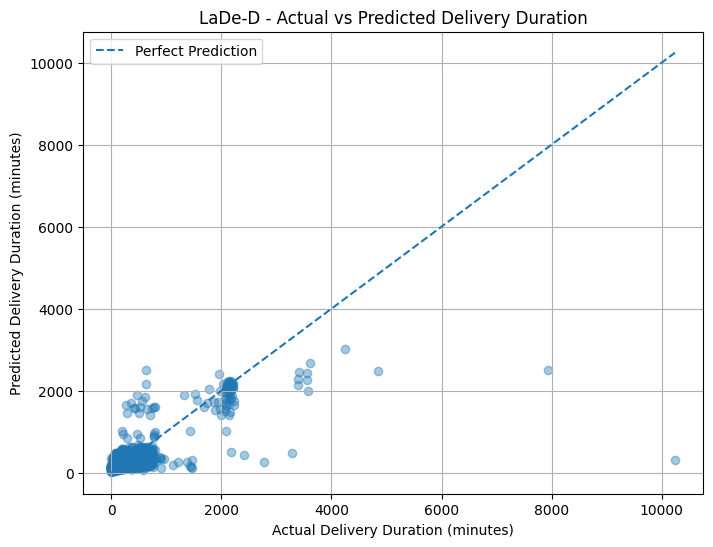

Actual vs Predicted graph saved successfully!


In [0]:
import matplotlib.pyplot as plt
import numpy as np

# Select 5,000 random test samples for visualization
rng = np.random.default_rng(42)

sample_size = min(5000, len(y_test))

indices = rng.choice(
    len(y_test),
    size=sample_size,
    replace=False
)

actual_sample = np.asarray(y_test)[indices]
predicted_sample = np.asarray(y_test_gb_pred)[indices]

# Plot
plt.figure(figsize=(8, 6))

plt.scatter(
    actual_sample,
    predicted_sample,
    alpha=0.4
)

# Perfect prediction reference line
min_value = min(actual_sample.min(), predicted_sample.min())
max_value = max(actual_sample.max(), predicted_sample.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Delivery Duration (minutes)")
plt.ylabel("Predicted Delivery Duration (minutes)")
plt.title("LaDe-D - Actual vs Predicted Delivery Duration")
plt.legend()
plt.grid()

plt.savefig(
    "/Volumes/workspace/supply_chain_db/supply_chain_data/lade_d_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Actual vs Predicted graph saved successfully!")

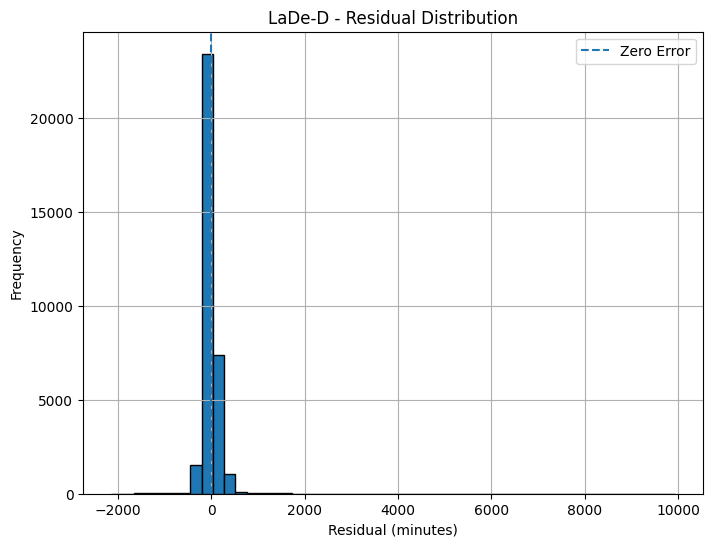

Mean Residual: -18.02
Residual graph saved successfully!


In [0]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate residuals
residuals = (
    np.asarray(y_test) -
    np.asarray(y_test_gb_pred)
)

# Plot residual distribution
plt.figure(figsize=(8, 6))

plt.hist(
    residuals,
    bins=50,
    edgecolor="black"
)

plt.axvline(
    0,
    linestyle="--",
    label="Zero Error"
)

plt.xlabel("Residual (minutes)")
plt.ylabel("Frequency")
plt.title("LaDe-D - Residual Distribution")
plt.legend()
plt.grid()

plt.savefig(
    "/Volumes/workspace/supply_chain_db/supply_chain_data/lade_d_residual_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Mean Residual:", round(float(np.mean(residuals)), 2))
print("Residual graph saved successfully!")

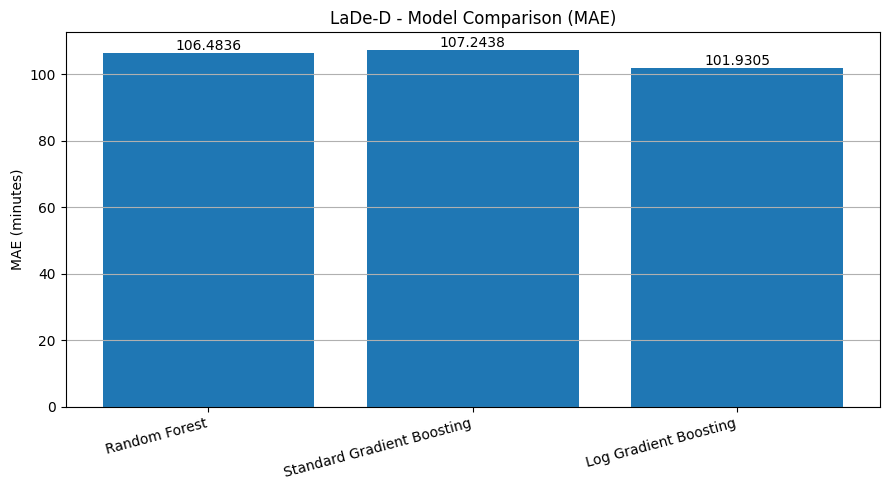

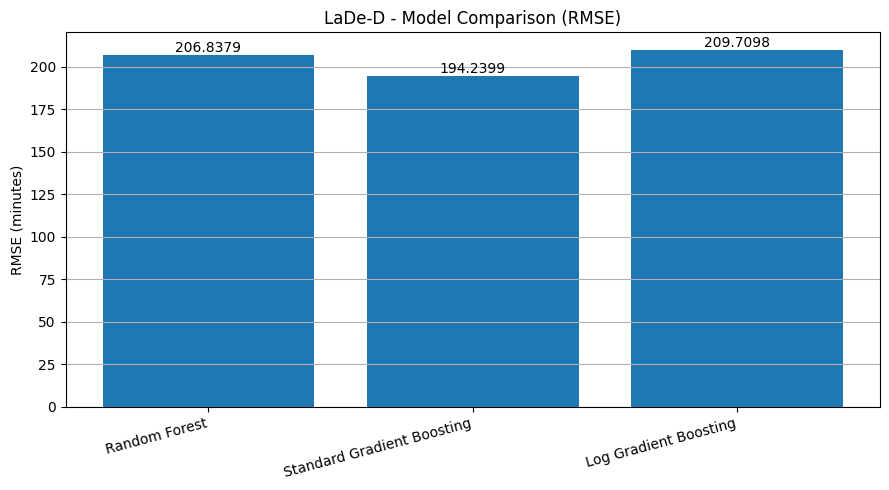

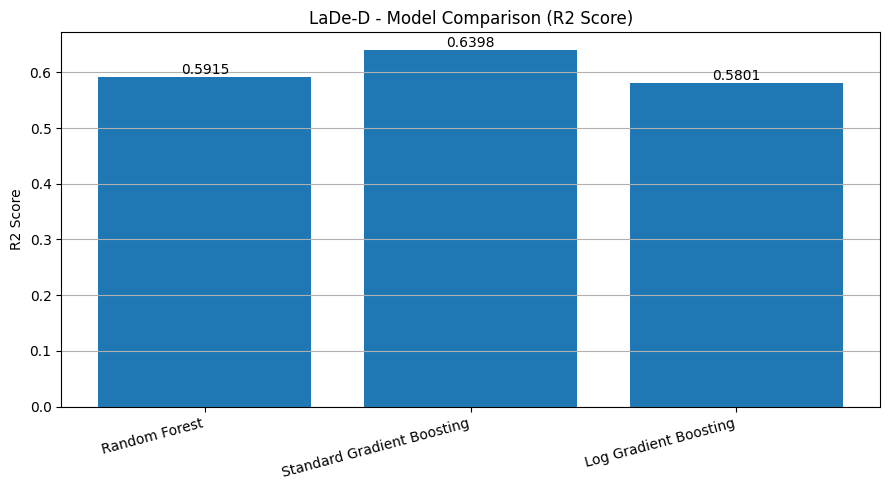

All model comparison graphs saved successfully!


In [0]:
import matplotlib.pyplot as plt

models = [
    "Random Forest",
    "Standard Gradient Boosting",
    "Log Gradient Boosting"
]

mae = [106.4836, 107.2438, 101.9305]
rmse = [206.8379, 194.2399, 209.7098]
r2 = [0.5915, 0.6398, 0.5801]

# Create three separate comparison plots
metrics = [
    ("MAE", mae, "MAE (minutes)", "lower"),
    ("RMSE", rmse, "RMSE (minutes)", "lower"),
    ("R2 Score", r2, "R2 Score", "higher")
]

for title, values, ylabel, direction in metrics:

    plt.figure(figsize=(9, 5))

    bars = plt.bar(models, values)

    plt.title(f"LaDe-D - Model Comparison ({title})")
    plt.ylabel(ylabel)
    plt.xticks(rotation=15, ha="right")
    plt.grid(axis="y")

    for bar, value in zip(bars, values):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:.4f}",
            ha="center",
            va="bottom"
        )

    plt.tight_layout()

    filename = title.lower().replace(" ", "_")

    plt.savefig(
        f"/Volumes/workspace/supply_chain_db/supply_chain_data/lade_d_{filename}_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("All model comparison graphs saved successfully!")